# Module 1: Forecasting Electricity Demand with Time-Series Foundation Models

In this notebook we forecast **Swiss hourly electricity demand one day ahead**, using pretrained
time-series **foundation models (FMs)** that we never train ourselves ("zero-shot").

**Learning goals**

- Understand what a time-series foundation model is and how zero-shot forecasting works.
- Load and explore real public data: Swiss electricity demand and weather.
- Compare simple baselines with two FMs (**Chronos-Bolt** and **Chronos-2**), and test whether adding weather helps.
- Evaluate forecasts over a full year, including how good the uncertainty ranges are.

**Runs locally** in the `fm4ues` conda environment (see the repository README). A GPU is used when available;
the notebook still works on CPU, just more slowly. Every main step is timed, and a runtime summary is shown at the end.

## 0. Setup and GPU check

This cell imports the libraries, finds the repository folder (so data paths work no matter where Jupyter was started),
and checks that PyTorch can see the GPU. It also defines a small `timed(...)` helper that records how long each step takes.

In [1]:
import time
import platform
import logging
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers

# Keep the output tidy: hide download/loading progress bars and a harmless Windows-only PyTorch notice
transformers.utils.logging.disable_progress_bar()
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

# Repository root = the first parent folder that contains requirements.txt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
CACHE = ROOT / "data" / "cache"          # downloaded data goes here (ignored by git)
CACHE.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.device_count() > 0 else "cpu"
# DEVICE = "cpu"   # <- uncomment to compare with CPU speed
print(f"Python  : {platform.python_version()}")
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"Data dir: {CACHE.relative_to(ROOT)}")

# Fix random seeds so results are reproducible
np.random.seed(0)
torch.manual_seed(0)

# --- Timing helper -------------------------------------------------------
TIMINGS = {}  # step name -> seconds

@contextmanager
def timed(step):
    # Measure the wall-clock time of a block of code and store it in TIMINGS.
    if DEVICE == "cuda":
        torch.cuda.synchronize()   # wait for pending GPU work so timings are honest
    start = time.perf_counter()
    yield
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    TIMINGS[step] = time.perf_counter() - start
    print(f"[time] {step}: {TIMINGS[step]:.1f} s")

plt.rcParams["figure.figsize"] = (12, 4)

Python  : 3.11.18
PyTorch : 2.11.0+cu128
Device  : cuda (Quadro RTX 6000)
Data dir: data\cache


## 1. What is a time-series foundation model?

A classic forecasting model is trained on **one** dataset, for example the history of one building's demand.

A **time-series foundation model** is trained once on a very large and varied collection of time series
(energy, traffic, weather, retail, ...). It learns general patterns such as daily and weekly cycles, trends and noise.
You can then give it the recent history of a **new** series it has never seen, and it forecasts the next values
directly. This is called **zero-shot forecasting**: no training on your data.

Key terms used below:

| Term | Meaning in this notebook |
| :--- | :--- |
| **Context** | The recent history we give the model (here 2,048 hours, about 12 weeks). |
| **Horizon** | How far ahead we forecast (here 24 hours: the next day). |
| **Quantiles** | Instead of one number, the model gives a range. The 0.1 and 0.9 quantiles form an 80% interval: the true value should fall inside it about 80% of the time. The 0.5 quantile (median) is our point forecast. |
| **Covariates** | Extra input series that help explain the target, here air temperature and solar radiation. |

We use two models from Amazon's open-source **Chronos** family:

- **Chronos-Bolt (base)**: about 200 M parameters, **univariate** (only looks at the demand history).
- **Chronos-2**: about 120 M parameters, can additionally use **covariates** such as weather.

## 2. Load the data

**Electricity demand:** hourly Swiss electricity consumption (MW) from the
[Open Power System Data](https://data.open-power-system-data.org/time_series/2020-10-06) "time_series" package
(column `CH_load_actual_entsoe_transparency`, originally from ENTSO-E). It covers 2015 to September 2020. We use 2016 onwards, because the first year (2015) contains some obvious data errors (spikes and drops).
The full file is about 130 MB. We download it once and keep only the Swiss column in a small cached file.

**Weather:** hourly air temperature (°C) and solar radiation (W/m²) for five Swiss cities from the free
[Open-Meteo historical weather API](https://open-meteo.com/en/docs/historical-weather-api), averaged into one national series.

All timestamps are in **UTC**, which avoids problems with daylight-saving time changes.

In [2]:
OPSD_URL = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"
LOAD_COL = "CH_load_actual_entsoe_transparency"
LOAD_FILE = CACHE / "opsd_ch_load.csv"

with timed("1. Load electricity demand (download on first run)"):
    if not LOAD_FILE.exists():
        print("Downloading OPSD data (~130 MB, only needed once) ...")
        raw = pd.read_csv(OPSD_URL, usecols=["utc_timestamp", LOAD_COL])
        raw.to_csv(LOAD_FILE, index=False)
    load = pd.read_csv(LOAD_FILE, index_col="utc_timestamp")[LOAD_COL].rename("load_mw")
    load.index = pd.to_datetime(load.index, utc=True).tz_localize(None)  # plain UTC timestamps

print(f"Loaded {len(load):,} hourly values")

[time] 1. Load electricity demand (download on first run): 0.0 s
Loaded 50,401 hourly values


In [3]:
# Keep the period with Swiss data and make sure every hour is present
load = load.loc["2016-01-01":"2020-09-30"].asfreq("h")  # skip 2015: contains data errors
print(f"Missing hours before cleaning: {load.isna().sum()}")

# Fill short gaps (up to 6 hours) by straight-line interpolation
load = load.interpolate(limit=6)
print(f"Missing hours after cleaning : {load.isna().sum()}")
print(load.describe().round(0))

Missing hours before cleaning: 1
Missing hours after cleaning : 0
count    41640.0
mean      6760.0
std        921.0
min       3722.0
25%       6089.0
50%       6731.0
75%       7342.0
max      10912.0
Name: load_mw, dtype: float64


In [4]:
WEATHER_FILE = CACHE / "openmeteo_ch_weather.csv"
CITIES = {  # name: (latitude, longitude)
    "Zurich": (47.37, 8.54), "Geneva": (46.20, 6.14), "Basel": (47.56, 7.59),
    "Bern": (46.95, 7.45), "Lugano": (46.01, 8.96),
}

with timed("2. Load weather (download on first run)"):
    if not WEATHER_FILE.exists():
        import requests
        print("Downloading weather from Open-Meteo ...")
        params = {
            "latitude": ",".join(str(lat) for lat, _ in CITIES.values()),
            "longitude": ",".join(str(lon) for _, lon in CITIES.values()),
            "start_date": "2016-01-01", "end_date": "2020-09-30",
            "hourly": "temperature_2m,shortwave_radiation", "timezone": "UTC",
        }
        resp = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
        resp.raise_for_status()
        per_city = [pd.DataFrame(loc["hourly"]).set_index("time") for loc in resp.json()]
        # Simple national average over the five cities
        weather_raw = sum(per_city) / len(per_city)
        weather_raw.to_csv(WEATHER_FILE)
    weather = pd.read_csv(WEATHER_FILE, index_col="time", parse_dates=["time"])
    weather.columns = ["temperature", "radiation"]

weather = weather.reindex(load.index).interpolate(limit=6)
df = pd.concat([load, weather], axis=1)
df.head()

[time] 2. Load weather (download on first run): 0.0 s


,load_mw,temperature,radiation
utc_timestamp,,,
2016-01-01 00:00:00,5953.75,4.94,0.0
2016-01-01 01:00:00,6047.29,4.84,0.0
2016-01-01 02:00:00,6199.22,4.80,0.0
2016-01-01 03:00:00,6112.67,4.98,0.0
2016-01-01 04:00:00,5891.14,5.06,0.0


## 3. Explore the data

Before forecasting, look at the patterns a good model should capture:
a **daily** cycle (low at night), a **weekly** cycle (lower at weekends) and a **seasonal** cycle (higher in winter).

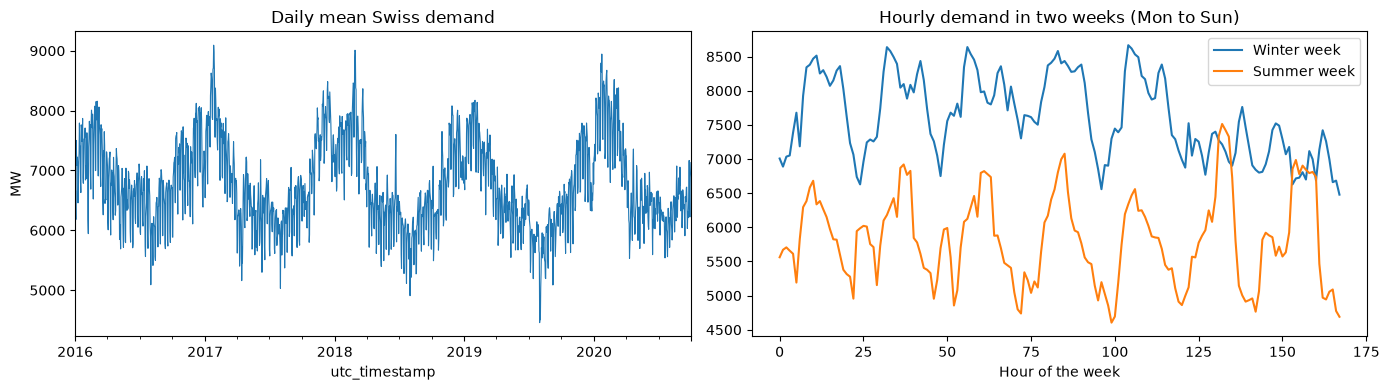

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Daily average demand over the whole period: seasonal cycle
df["load_mw"].resample("D").mean().plot(ax=axes[0], lw=0.8)
axes[0].set_title("Daily mean Swiss demand")
axes[0].set_ylabel("MW")

# Two example weeks: daily + weekly cycles, winter vs. summer
for start, label in [("2019-01-14", "Winter week"), ("2019-07-15", "Summer week")]:
    week = df.loc[start:pd.Timestamp(start) + pd.Timedelta("6D23h"), "load_mw"]
    axes[1].plot(np.arange(len(week)), week.values, label=label)
axes[1].set_title("Hourly demand in two weeks (Mon to Sun)")
axes[1].set_xlabel("Hour of the week")
axes[1].legend()
plt.tight_layout()
plt.show()

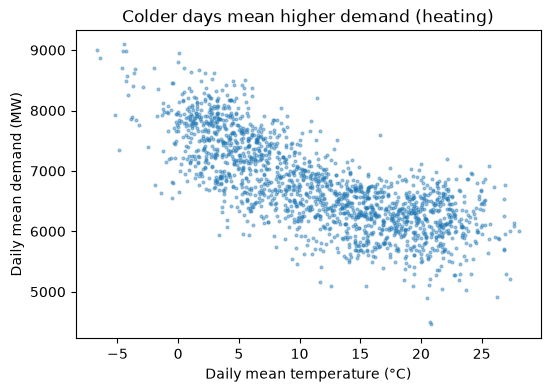

In [6]:
# How does demand relate to temperature? (daily means)
daily = df.resample("D").mean()
plt.figure(figsize=(6, 4))
plt.scatter(daily["temperature"], daily["load_mw"], s=4, alpha=0.4)
plt.xlabel("Daily mean temperature (°C)")
plt.ylabel("Daily mean demand (MW)")
plt.title("Colder days mean higher demand (heating)")
plt.show()

## 4. Forecasting set-up and simple baselines

We simulate a **day-ahead forecast** for every day of **2019** (365 forecasts):
at midnight (UTC) we use the last 2,048 hours of demand as context and forecast the next 24 hours.

Every forecast is compared with two **baselines**. A foundation model is only useful if it beats them:

- **Yesterday**: tomorrow looks exactly like today (repeat the last 24 hours).
- **Last week**: tomorrow looks like the same weekday last week (repeat the values from 168 hours earlier).

In [7]:
CONTEXT = 2048        # hours of history given to the models (~12 weeks)
HORIZON = 24          # hours to forecast
QUANTILES = [0.1, 0.5, 0.9]

origins = pd.date_range("2019-01-01", "2019-12-31", freq="D")   # forecast start times
y = df["load_mw"]
pos = {t: i for i, t in enumerate(y.index)}                       # timestamp -> row number

def window(series, start_idx, length):
    return series.values[start_idx:start_idx + length]

# Actual demand for each forecast day: shape (365, 24)
actual = np.stack([window(y, pos[o], HORIZON) for o in origins])
# Demand history given to the models: shape (365, 2048)
contexts = np.stack([window(y, pos[o] - CONTEXT, CONTEXT) for o in origins])
assert not np.isnan(actual).any() and not np.isnan(contexts).any(), "gaps left in the data"

forecasts = {}   # model name -> median forecast, shape (365, 24)
intervals = {}   # model name -> (10% quantile, 90% quantile)

with timed("3. Baseline forecasts"):
    forecasts["Yesterday"] = np.stack([window(y, pos[o] - 24, HORIZON) for o in origins])
    forecasts["Last week"] = np.stack([window(y, pos[o] - 168, HORIZON) for o in origins])

print(f"{len(origins)} forecast days, context {contexts.shape[1]} h, horizon {HORIZON} h")

[time] 3. Baseline forecasts: 0.0 s
365 forecast days, context 2048 h, horizon 24 h


## 5. Zero-shot forecast with Chronos-Bolt (demand only)

We download the pretrained model from Hugging Face (about 0.8 GB, cached after the first run),
then forecast all 365 days in one batched call on the GPU.

In [8]:
from chronos import BaseChronosPipeline

with timed("4. Load Chronos-Bolt (download on first run)"):
    bolt = BaseChronosPipeline.from_pretrained(
        "amazon/chronos-bolt-base", device_map=DEVICE, torch_dtype=torch.float32
    )

with timed("5. Chronos-Bolt: forecast 365 days"):
    q, _ = bolt.predict_quantiles(
        torch.tensor(contexts, dtype=torch.float32),
        prediction_length=HORIZON,
        quantile_levels=QUANTILES,
    )
q = q.numpy()                        # shape (365, 24, 3)
forecasts["Chronos-Bolt"] = q[..., 1]
intervals["Chronos-Bolt"] = (q[..., 0], q[..., 2])

[time] 4. Load Chronos-Bolt (download on first run): 2.2 s


[time] 5. Chronos-Bolt: forecast 365 days: 1.4 s


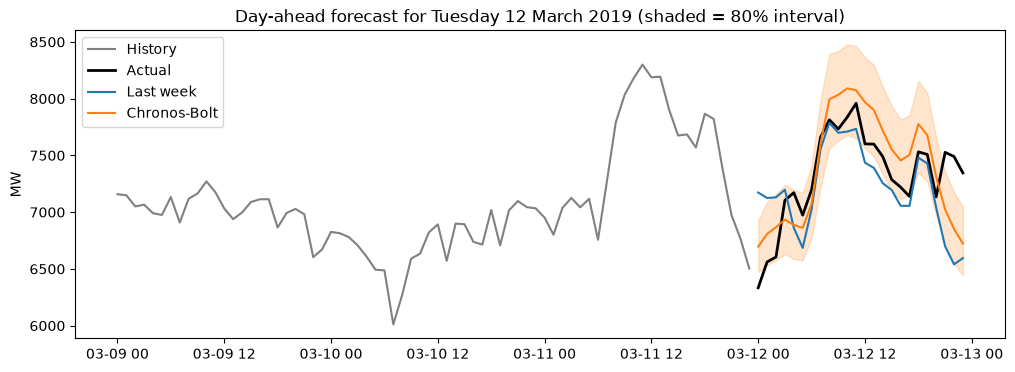

In [9]:
def plot_day(day, models):
    # Plot one forecast day: actual demand, each model's median and the 80% interval.
    i = list(origins).index(pd.Timestamp(day))
    hours = pd.date_range(origins[i], periods=HORIZON, freq="h")
    history = y.loc[origins[i] - pd.Timedelta("72h"):origins[i] - pd.Timedelta("1h")]
    plt.plot(history.index, history.values, color="grey", label="History")
    plt.plot(hours, actual[i], color="black", lw=2, label="Actual")
    for m in models:
        line, = plt.plot(hours, forecasts[m][i], label=m)
        if m in intervals:
            lo, hi = intervals[m]
            plt.fill_between(hours, lo[i], hi[i], color=line.get_color(), alpha=0.2)
    plt.ylabel("MW")
    plt.title(f"Day-ahead forecast for {origins[i]:%A %d %B %Y} (shaded = 80% interval)")
    plt.legend()
    plt.show()

plot_day("2019-03-12", ["Last week", "Chronos-Bolt"])

## 6. Chronos-2: does weather help?

Chronos-2 accepts **covariates**. We run it twice:

1. **Chronos-2 (demand only)**: same input as Chronos-Bolt, for a fair comparison.
2. **Chronos-2 + weather**: we also give past *and future* temperature and radiation.

Note: for the future 24 hours we use the **measured** weather, as if we had a perfect weather forecast.
In real operation you would use a weather forecast instead, which would make the gain somewhat smaller.

Chronos-2 takes its input as a table (pandas DataFrame): one row per hour, with an `id` column telling
which forecast (day) the row belongs to.

In [10]:
from chronos import Chronos2Pipeline

def make_frames(with_weather):
    # Build the context table (history) and future table (known future inputs) for all 365 forecasts.
    ctx_parts, fut_parts = [], []
    cols = ["load_mw", "temperature", "radiation"] if with_weather else ["load_mw"]
    for k, o in enumerate(origins):
        hist = df.iloc[pos[o] - CONTEXT:pos[o]][cols].reset_index(names="timestamp")
        hist.insert(0, "id", k)
        ctx_parts.append(hist)
        if with_weather:
            fut = df.iloc[pos[o]:pos[o] + HORIZON][["temperature", "radiation"]].reset_index(names="timestamp")
            fut.insert(0, "id", k)
            fut_parts.append(fut)
    ctx = pd.concat(ctx_parts, ignore_index=True)
    fut = pd.concat(fut_parts, ignore_index=True) if with_weather else None
    return ctx, fut

def run_chronos2(with_weather):
    ctx, fut = make_frames(with_weather)
    pred = chronos2.predict_df(
        ctx, future_df=fut, id_column="id", timestamp_column="timestamp", target="load_mw",
        prediction_length=HORIZON, quantile_levels=QUANTILES,
    )
    pred = pred.sort_values(["id", "timestamp"])
    get = lambda col: pred[col].to_numpy().reshape(len(origins), HORIZON)
    return get("0.5"), (get("0.1"), get("0.9"))

with timed("6. Load Chronos-2 (download on first run)"):
    chronos2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)

with timed("7. Chronos-2 (demand only): forecast 365 days"):
    forecasts["Chronos-2"], intervals["Chronos-2"] = run_chronos2(with_weather=False)

with timed("8. Chronos-2 + weather: forecast 365 days"):
    forecasts["Chronos-2 + weather"], intervals["Chronos-2 + weather"] = run_chronos2(with_weather=True)

[time] 6. Load Chronos-2 (download on first run): 1.5 s


[time] 7. Chronos-2 (demand only): forecast 365 days: 2.0 s


[time] 8. Chronos-2 + weather: forecast 365 days: 5.2 s


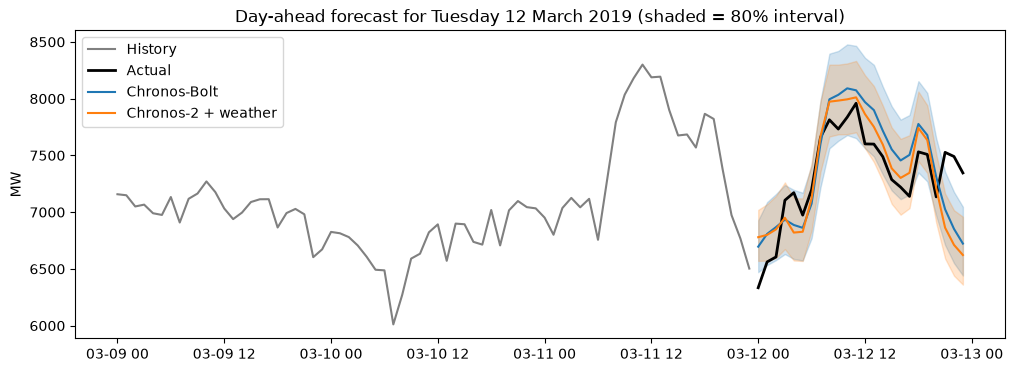

In [11]:
plot_day("2019-03-12", ["Chronos-Bolt", "Chronos-2 + weather"])

## 7. Evaluate over the whole year

One nice-looking day proves little, so we score all 365 forecasts:

- **MAE** (mean absolute error, MW): the average size of the error. Lower is better.
- **MAPE** (mean absolute percentage error, %): the same error relative to demand. Lower is better.
- **80% interval coverage**: how often the actual value fell inside the 10–90% range. Ideally close to **80%**.
  Much lower means the model is over-confident; much higher means the range is wider than needed.

,MAE (MW),MAPE (%),80% coverage (%)
Model,,,
Last week,401.9,6.4,NaN
Yesterday,395.0,6.2,NaN
Chronos-Bolt,254.5,4.0,78.5
Chronos-2,247.3,3.9,77.4
Chronos-2 + weather,242.0,3.8,76.6


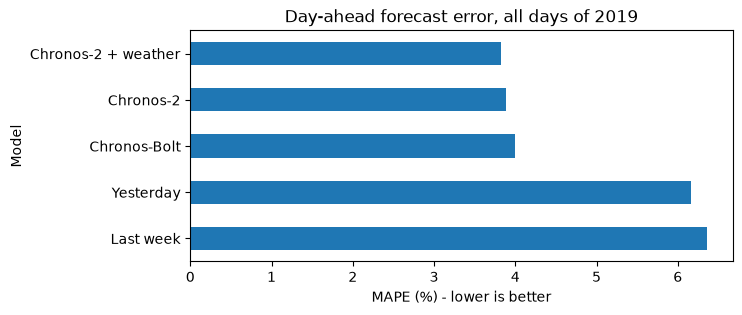

In [12]:
rows = []
for name, pred in forecasts.items():
    err = np.abs(pred - actual)
    row = {"Model": name, "MAE (MW)": err.mean(), "MAPE (%)": 100 * (err / actual).mean()}
    if name in intervals:
        lo, hi = intervals[name]
        row["80% coverage (%)"] = 100 * ((actual >= lo) & (actual <= hi)).mean()
    rows.append(row)

results = pd.DataFrame(rows).set_index("Model").sort_values("MAE (MW)", ascending=False)
display(results.round(1))

ax = results["MAPE (%)"].plot.barh(figsize=(7, 3), color="tab:blue")
ax.set_xlabel("MAPE (%) - lower is better")
ax.set_title("Day-ahead forecast error, all days of 2019")
plt.show()

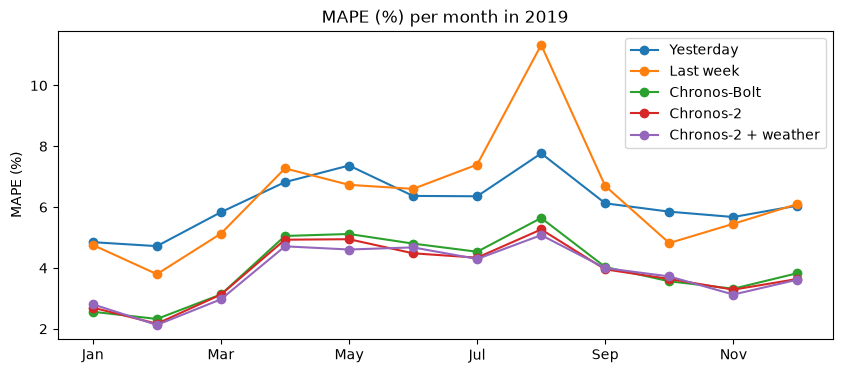

In [13]:
# Error by month: where do the models struggle? (look at August: summer holidays)
monthly = pd.DataFrame(
    {m: 100 * (np.abs(forecasts[m] - actual) / actual).mean(axis=1) for m in forecasts},
    index=origins,
).resample("MS").mean()
monthly.index = monthly.index.strftime("%b")
monthly.plot(marker="o", figsize=(10, 4), title="MAPE (%) per month in 2019")
plt.ylabel("MAPE (%)")
plt.show()

**How to read the results**

- Both foundation models should clearly beat the two baselines, **without any training on Swiss data**.
  That is the main point of zero-shot forecasting.
- Weather usually gives only a **small** extra gain for day-ahead national demand. The last 12 weeks of demand
  already contain most of the information, and temperature changes slowly from one day to the next.
- Check whether the 80% coverage is close to 80%. If it is a bit lower, the models are slightly over-confident.
- All models are worst in **August**, the Swiss summer holiday period. Demand is unusually low then, and
  "yesterday" or "last week" stop being good guides.

## 8. Runtime summary

How long each step took on this machine. Steps marked "download on first run" are much faster on later runs,
because data and model weights are cached on disk.

In [14]:
timing_table = pd.Series(TIMINGS, name="seconds").round(1).to_frame()
timing_table.loc["Total (timed steps)"] = timing_table["seconds"].sum().round(1)
gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only"
print(f"Hardware: {gpu}")
display(timing_table)

# Also save to a CSV file so runs on different machines can be compared
timing_table.assign(device=gpu).to_csv(CACHE / "module1_runtime.csv")

Hardware: Quadro RTX 6000


,seconds
1. Load electricity demand (download on first run),0.0
2. Load weather (download on first run),0.0
3. Baseline forecasts,0.0
4. Load Chronos-Bolt (download on first run),2.2
5. Chronos-Bolt: forecast 365 days,1.4
6. Load Chronos-2 (download on first run),1.5
7. Chronos-2 (demand only): forecast 365 days,2.0
8. Chronos-2 + weather: forecast 365 days,5.2
Total (timed steps),12.3


## 9. Things to try

- **Context length:** change `CONTEXT` to 168 (one week) or 512. Does accuracy drop?
- **Horizon:** forecast 48 or 168 hours instead of 24.
- **Holidays:** look at the forecasts in the August holidays or around Christmas (`plot_day("2019-12-25", ...)`). Can you add a holiday flag as an extra covariate for Chronos-2?
- **CPU vs. GPU:** uncomment `DEVICE = "cpu"` in the setup cell and compare the runtime summary.
- **Other FMs:** try another time-series foundation model, for example Google's TimesFM, on the same `contexts` array.